# 02 · A/B test: one-page checkout

> **Simulated data.** Generated by `pulso_exp.simulate` (seed 42). The simulator plants a known effect, which lets
> the last section check the analysis against ground truth. Pulso is a fictional company.

**Change under test:** merchants creating an order go through checkout in three screens (quote → details → payment).
Variant B merges details and payment into **one page**. Merchants are bucketed 50/50 by a hash of `merchant_id`
(the way a feature-flag service would do it), so a merchant sees the same checkout for the whole test.

Outline: pre-registration → power & sample size → SRM → primary metric (z-test) → secondary metric with CUPED →
guardrails → novelty → Bayesian read-out → why peeking is not allowed → ground-truth check → decision.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as st

from pulso_exp.clean import clean_orders, clean_sessions, find_bot_merchants
from pulso_exp.plotting import ARM_COLORS, INK_SECONDARY, SERIES, TREATMENT, apply_style
from pulso_exp.simulate import SimConfig, simulate, uplift_multiplier
from pulso_exp.stats import (
    beta_binomial_ab,
    cuped,
    mde_proportions,
    sample_size_means,
    sample_size_proportions,
    simulate_peeking,
    srm_check,
    two_proportion_ztest,
    welch_ttest,
)

apply_style()
cfg = SimConfig()
data = simulate(cfg)
bots = find_bot_merchants(data.sessions)
sessions = clean_sessions(data.sessions)
orders = clean_orders(data.orders, bot_merchants=bots)
merchants = data.merchants[~data.merchants["merchant_id"].isin(bots)].set_index("merchant_id")
print(f"{len(merchants):,} merchants · {len(sessions):,} clean sessions · {len(orders):,} orders")
print(
    "experiment window:",
    cfg.experiment_start.date(),
    "→",
    (cfg.experiment_start + pd.Timedelta(days=cfg.exp_days - 1)).date(),
)

60,000 merchants · 166,019 clean sessions · 56,071 orders
experiment window: 2026-03-30 → 2026-04-26


## 1 · Pre-registration

Written **before** looking at any experiment-period data (only the pre-period informs the numbers).

| item | choice |
|---|---|
| **Hypothesis** | Merging details + payment removes a screen where merchants drop off, so more merchants who start a checkout end up placing a paid order. |
| **Randomisation unit** | merchant (hash bucketing, 50/50). Sessions of one merchant are not independent, so the analysis unit is also the merchant. |
| **Population (trigger)** | merchants with ≥ 1 checkout session during the 28-day window. Exposure is decided before the variant can matter, so triggering does not bias the comparison. |
| **Primary metric** | *merchant checkout conversion*: share of triggered merchants with ≥ 1 paid order in the window. Two-sided two-proportion z-test, α = 0.05. |
| **Secondary metric** | net GMV per triggered merchant (MXN, delivered orders). Welch t-test, with CUPED on pre-period GMV. |
| **Guardrails** | p95 checkout page load (must not worsen > 5 %), payment failure rate among submitted payments, order cancellation rate. |
| **MDE / power** | 3 % relative on the primary metric, 80 % power. |
| **Duration** | 28 days = 4 full weeks (covers weekly cycles), fixed in advance. **No early stopping.** |
| **Decision rule** | Ship if the primary metric is significantly positive and no guardrail is breached. |

## 2 · Power analysis and sample size

The pre-period (same 28-day length, everyone on the old checkout) gives the baseline and the expected traffic.

In [2]:
def merchant_metrics(s: pd.DataFrame, o: pd.DataFrame) -> pd.DataFrame:
    """One row per merchant with >= 1 session in the given slice."""
    m = s.groupby("merchant_id").agg(
        sessions=("session_id", "size"),
        converted=("funnel_step", lambda x: (x == "paid").any()),
    )
    gmv = o[o["status"] == "DELIVERED"].groupby("merchant_id")["amount_cents"].sum() / 100
    m["gmv"] = gmv.reindex(m.index).fillna(0.0)
    return m


pre = merchant_metrics(sessions[sessions["period"] == "pre"], orders[orders["period"] == "pre"])
baseline = pre["converted"].mean()
expected_per_arm = len(pre) // 2
n_needed = sample_size_proportions(baseline, mde_relative=0.03, alpha=0.05, power=0.8)

print(f"baseline merchant conversion (pre-period): {baseline:.2%}")
print(f"merchants triggered in a 28-day window:    {len(pre):,}  → ~{expected_per_arm:,} per arm")
print(f"needed per arm for a 3% relative MDE:      {n_needed:,}")
print(
    f"MDE achievable with {expected_per_arm:,} per arm:       {mde_proportions(baseline, expected_per_arm):.2%} relative"
)

pd.DataFrame(
    {"n per arm": [sample_size_proportions(baseline, m) for m in (0.02, 0.03, 0.05, 0.10)]},
    index=pd.Index(["2%", "3%", "5%", "10%"], name="relative MDE"),
).style.format("{:,}")

baseline merchant conversion (pre-period): 51.80%
merchants triggered in a 28-day window:    34,358  → ~17,179 per arm
needed per arm for a 3% relative MDE:      16,204
MDE achievable with 17,179 per arm:       2.91% relative


,n per arm
relative MDE,
2%,"36,478"
3%,"16,204"
5%,"5,826"
10%,"1,450"


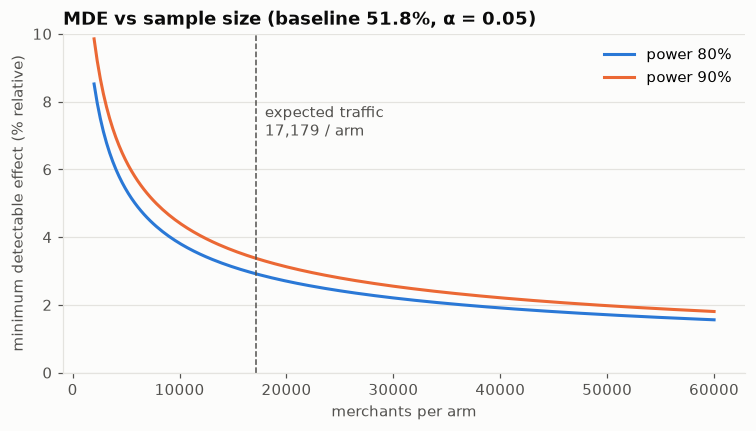

In [3]:
n_grid = np.linspace(2_000, 60_000, 200)
fig, ax = plt.subplots()
for i, pw in enumerate((0.8, 0.9)):
    ax.plot(
        n_grid,
        [mde_proportions(baseline, int(n), power=pw) * 100 for n in n_grid],
        color=SERIES[i],
        label=f"power {pw:.0%}",
    )
ax.axvline(expected_per_arm, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.annotate(
    f"expected traffic\n{expected_per_arm:,} / arm",
    xy=(expected_per_arm + 800, 7),
    color=INK_SECONDARY,
)
ax.set_ylim(0, 10)
ax.set_xlabel("merchants per arm")
ax.set_ylabel("minimum detectable effect (% relative)")
ax.set_title(f"MDE vs sample size (baseline {baseline:.1%}, α = 0.05)")
ax.legend()
plt.show()

Four weeks of traffic is just enough for a 3 % relative MDE at 80 % power; the curve shows how quickly the MDE
grows if the test is cut short. The secondary metric is a different story: GMV per merchant is heavy-tailed.

In [4]:
gmv_sd, gmv_mean = pre["gmv"].std(), pre["gmv"].mean()
print(
    f"pre-period GMV per triggered merchant: mean {gmv_mean:,.0f} MXN, sd {gmv_sd:,.0f} MXN (CV {gmv_sd / gmv_mean:.2f})"
)
print(f"n per arm to detect +3% GMV: {sample_size_means(gmv_sd, 0.03 * gmv_mean):,}")

pre-period GMV per triggered merchant: mean 443 MXN, sd 913 MXN (CV 2.06)
n per arm to detect +3% GMV: 74,063


With raw GMV we would need several times the traffic we have. **CUPED** (section 5) is how we recover
sensitivity without running longer.

## 3 · Sample ratio mismatch (SRM)

Before reading any metric: did the split come out as designed? An SRM means the assignment or the logging is broken,
and then no metric comparison can be trusted. The threshold is strict (p < 0.001) because the check runs on every test.

In [5]:
exp_sessions = sessions[sessions["period"] == "experiment"]
exp = merchant_metrics(exp_sessions, orders[orders["period"] == "experiment"]).join(
    merchants["variant"]
)

assigned = merchants["variant"].value_counts().sort_index()
triggered = exp["variant"].value_counts().sort_index()
pd.DataFrame(
    [
        {
            "population": name,
            "control": int(c["control"]),
            "treatment": int(c["treatment"]),
            "treatment share": c["treatment"] / c.sum(),
            "chi²": r.chi2,
            "p-value": r.p_value,
            "SRM?": r.mismatch,
        }
        for name, c in (
            ("assigned (all merchants)", assigned),
            ("triggered (≥1 session)", triggered),
        )
        for r in [srm_check(c.tolist())]
    ]
).style.format(
    {
        "control": "{:,}",
        "treatment": "{:,}",
        "treatment share": "{:.2%}",
        "chi²": "{:.2f}",
        "p-value": "{:.3f}",
    }
)

,population,control,treatment,treatment share,chi²,p-value,SRM?
0,assigned (all merchants),"30,137","29,863",49.77%,1.25,0.263,False
1,triggered (≥1 session),"17,404","17,012",49.43%,4.46,0.035,False


No SRM. The triggered split has p ≈ 0.03 — that would look "significant" at 0.05, which is exactly why SRM uses
0.001: with dozens of experiments a 0.05 threshold would raise false alarms every week. Since assignment itself is
balanced and the trigger (opening checkout) happens before the new page is seen, this is chance, not a bug.

**Raw-data duplicates would have mattered here:** on the uncleaned session table, an ingestion retry that only hit one
platform could create a fake session imbalance. Counting merchants (the randomisation unit), not sessions, avoids that.

## 4 · Primary metric: merchant checkout conversion

In [6]:
ctrl, trt = exp[exp["variant"] == "control"], exp[exp["variant"] == "treatment"]
primary = two_proportion_ztest(
    int(ctrl["converted"].sum()), len(ctrl), int(trt["converted"].sum()), len(trt)
)

print(f"control   {primary.control:.2%}  (n={len(ctrl):,})")
print(f"treatment {primary.treatment:.2%}  (n={len(trt):,})")
print(
    f"difference {primary.diff * 100:+.2f} pp  95% CI [{primary.ci_low * 100:+.2f}, {primary.ci_high * 100:+.2f}] pp"
)
print(
    f"relative   {primary.relative:+.2%}  95% CI [{primary.ci_low / primary.control:+.2%}, {primary.ci_high / primary.control:+.2%}]"
)
print(f"z = {primary.statistic:.2f}, p = {primary.p_value:.2g}")

control   51.93%  (n=17,404)
treatment 54.29%  (n=17,012)
difference +2.35 pp  95% CI [+1.30, +3.41] pp
relative   +4.53%  95% CI [+2.50%, +6.56%]
z = 4.38, p = 1.2e-05


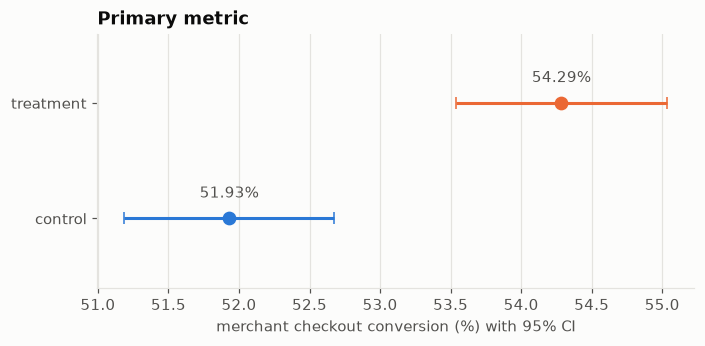

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
for i, (arm, df) in enumerate((("control", ctrl), ("treatment", trt))):
    p = df["converted"].mean()
    se = np.sqrt(p * (1 - p) / len(df))
    ax.errorbar(
        p * 100,
        i,
        xerr=1.96 * se * 100,
        fmt="o",
        color=ARM_COLORS[arm],
        markersize=8,
        capsize=4,
        linewidth=2,
    )
    ax.annotate(f"{p:.2%}", xy=(p * 100, i + 0.18), ha="center", color=INK_SECONDARY)
ax.set_yticks([0, 1], ["control", "treatment"])
ax.set_ylim(-0.6, 1.6)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("merchant checkout conversion (%) with 95% CI")
ax.set_title("Primary metric")
plt.show()

The one-page checkout lifts merchant conversion, and the whole 95 % CI is above zero.

## 5 · Secondary metric: GMV per merchant, with CUPED

CUPED (Controlled-experiment Using Pre-Experiment Data, Deng et al. 2013) subtracts the part of each merchant's metric
that was predictable from **before** the experiment:

$$Y^{cuped}_i = Y_i - \theta\,(X_i - \bar X), \qquad \theta = \frac{\operatorname{cov}(Y, X)}{\operatorname{var}(X)}$$

`X` = the same merchant's pre-period GMV (0 if they were not active). Because `X` is measured before assignment it
cannot be affected by the treatment, so the estimate stays unbiased; the variance shrinks by a factor of
(1 − ρ²).

In [8]:
exp = exp.join(pre[["gmv", "converted"]].add_prefix("pre_"))
exp[["pre_gmv"]] = exp[["pre_gmv"]].fillna(0.0)
exp["pre_converted"] = exp["pre_converted"].fillna(False).astype(float)

gmv_cuped = cuped(exp["gmv"].to_numpy(), exp["pre_gmv"].to_numpy())
exp["gmv_cuped"] = gmv_cuped.adjusted
is_t = (exp["variant"] == "treatment").to_numpy()

raw = welch_ttest(exp.loc[~is_t, "gmv"], exp.loc[is_t, "gmv"])
adj = welch_ttest(exp.loc[~is_t, "gmv_cuped"], exp.loc[is_t, "gmv_cuped"])
print(
    f"corr(GMV, pre-GMV) = {np.corrcoef(exp['gmv'], exp['pre_gmv'])[0, 1]:.3f}  → θ = {gmv_cuped.theta:.3f}, variance reduction {gmv_cuped.variance_reduction:.1%}"
)
print(f"equivalent to {1 / (1 - gmv_cuped.variance_reduction):.2f}x the sample size, for free")

gmv_table = pd.DataFrame(
    [
        {
            "estimator": name,
            "Δ GMV / merchant (MXN)": r.diff,
            "95% CI low": r.ci_low,
            "95% CI high": r.ci_high,
            "relative": r.relative,
            "p-value": r.p_value,
        }
        for name, r in (("raw Welch", raw), ("CUPED Welch", adj))
    ]
).set_index("estimator")
gmv_table.style.format(
    {
        "Δ GMV / merchant (MXN)": "{:+.1f}",
        "95% CI low": "{:+.1f}",
        "95% CI high": "{:+.1f}",
        "relative": "{:+.2%}",
        "p-value": "{:.3f}",
    }
)

corr(GMV, pre-GMV) = 0.405  → θ = 0.402, variance reduction 16.4%
equivalent to 1.20x the sample size, for free


,Δ GMV / merchant (MXN),95% CI low,95% CI high,relative,p-value
estimator,,,,,
raw Welch,+14.4,-4.2,+33.1,+3.25%,0.129
CUPED Welch,+19.9,+2.8,+36.9,+4.50%,0.022


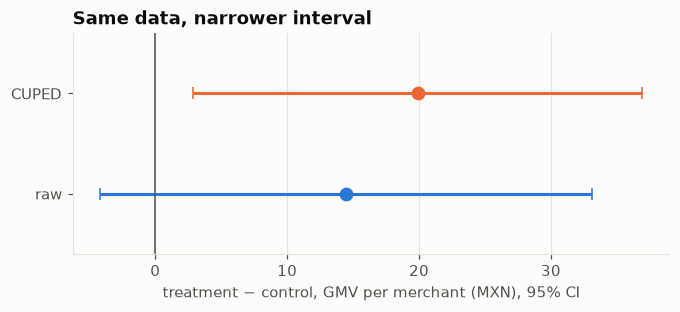

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.6))
for i, r in enumerate((raw, adj)):
    ax.errorbar(
        r.diff,
        i,
        xerr=[[r.diff - r.ci_low], [r.ci_high - r.diff]],
        fmt="o",
        color=SERIES[i],
        markersize=8,
        capsize=4,
        linewidth=2,
    )
ax.axvline(0, color=INK_SECONDARY, linewidth=1)
ax.set_yticks([0, 1], ["raw", "CUPED"])
ax.set_ylim(-0.6, 1.6)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("treatment − control, GMV per merchant (MXN), 95% CI")
ax.set_title("Same data, narrower interval")
plt.show()

The raw comparison cannot tell a GMV effect from noise; after CUPED the interval narrows and excludes zero.
The point estimate moves a little too — expected, since CUPED also corrects the chance pre-period imbalance between arms.

CUPED is only as good as the covariate. On the binary primary metric, the obvious covariate (did the merchant convert
in the pre-period?) is weak: most triggered merchants have no pre-period purchase at all, so the covariate is a
constant 0 for them and explains little:

In [10]:
conv_cuped = cuped(exp["converted"].astype(float).to_numpy(), exp["pre_converted"].to_numpy())
print(f"CUPED on conversion: variance reduction {conv_cuped.variance_reduction:.1%}")
print(f"triggered merchants with zero pre-period GMV: {exp['pre_gmv'].eq(0).mean():.1%}")

CUPED on conversion: variance reduction 2.8%
triggered merchants with zero pre-period GMV: 62.0%


Small gain, so the primary read-out stays on the simpler, pre-registered z-test.

## 6 · Guardrails

A win on the primary metric does not ship if it breaks something else.

In [11]:
rng = np.random.default_rng(7)


def bootstrap_p95_diff(
    a: np.ndarray, b: np.ndarray, n_boot: int = 500
) -> tuple[float, float, float]:
    """Relative change in p95 (b vs a) with a percentile bootstrap CI."""
    point = np.percentile(b, 95) / np.percentile(a, 95) - 1
    boots = [
        np.percentile(rng.choice(b, b.size), 95) / np.percentile(rng.choice(a, a.size), 95) - 1
        for _ in range(n_boot)
    ]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return point, lo, hi


lat = exp_sessions.dropna(subset=["page_load_ms"])
lat_c = lat.loc[lat["variant"] == "control", "page_load_ms"].to_numpy()
lat_t = lat.loc[lat["variant"] == "treatment", "page_load_ms"].to_numpy()
p95 = bootstrap_p95_diff(lat_c, lat_t)

submitted = exp_sessions[exp_sessions["funnel_step"].isin(["payment_submitted", "paid"])]
fail = [
    submitted.loc[submitted["variant"] == v, "payment_failed"] for v in ("control", "treatment")
]
pay = two_proportion_ztest(int(fail[0].sum()), len(fail[0]), int(fail[1].sum()), len(fail[1]))

eo = orders[orders["period"] == "experiment"]
canc = [eo.loc[eo["variant"] == v, "status"].eq("CANCELLED") for v in ("control", "treatment")]
cancel = two_proportion_ztest(int(canc[0].sum()), len(canc[0]), int(canc[1].sum()), len(canc[1]))

guardrails = pd.DataFrame(
    [
        {
            "guardrail": "p95 checkout page load",
            "control": f"{np.percentile(lat_c, 95):,.0f} ms",
            "treatment": f"{np.percentile(lat_t, 95):,.0f} ms",
            "relative change": p95[0],
            "95% CI": f"[{p95[1]:+.1%}, {p95[2]:+.1%}]",
            "limit": "≤ +5%",
            "flag": p95[0] > 0.05,
        },
        {
            "guardrail": "payment failure rate",
            "control": f"{pay.control:.2%}",
            "treatment": f"{pay.treatment:.2%}",
            "relative change": pay.relative,
            "95% CI": f"[{pay.ci_low / pay.control:+.1%}, {pay.ci_high / pay.control:+.1%}]",
            "limit": "not sig. worse",
            "flag": pay.diff > 0 and pay.p_value < 0.05,
        },
        {
            "guardrail": "order cancellation rate",
            "control": f"{cancel.control:.2%}",
            "treatment": f"{cancel.treatment:.2%}",
            "relative change": cancel.relative,
            "95% CI": f"[{cancel.ci_low / cancel.control:+.1%}, {cancel.ci_high / cancel.control:+.1%}]",
            "limit": "not sig. worse",
            "flag": cancel.diff > 0 and cancel.p_value < 0.05,
        },
    ]
).set_index("guardrail")
guardrails["p-value"] = [np.nan, pay.p_value, cancel.p_value]
guardrails.style.format({"relative change": "{:+.1%}", "p-value": "{:.3f}"}, na_rep="—")

,control,treatment,relative change,95% CI,limit,flag,p-value
guardrail,,,,,,,
p95 checkout page load,"1,490 ms","1,517 ms",+1.8%,"[+0.7%, +3.0%]",≤ +5%,False,—
payment failure rate,6.97%,6.90%,-1.0%,"[-9.1%, +7.2%]",not sig. worse,False,0.816
order cancellation rate,2.96%,3.41%,+15.4%,"[+1.6%, +29.3%]",not sig. worse,True,0.029


**Cancellation rate is flagged**: +15 % relative, p ≈ 0.03 at the unadjusted 5 % level. Before acting on it, two checks
that should have been in the pre-registration:

1. **Multiplicity.** Three guardrails were tested; with a Holm correction the smallest p-value must clear 0.05 / 2
   (the latency guardrail is a threshold, not a test, so two tests remain).
2. **Clustering.** Cancellations are order-level but merchants were randomised; a merchant-level (cluster) bootstrap
   gives the honest interval.

In [12]:
from statsmodels.stats.multitest import multipletests

holm = multipletests([pay.p_value, cancel.p_value], alpha=0.05, method="holm")
print(f"Holm-adjusted p-values: payment failure {holm[1][0]:.3f}, cancellation {holm[1][1]:.3f}")

per_m = (
    eo.assign(cancelled=eo["status"].eq("CANCELLED"))
    .groupby(["variant", "merchant_id"])["cancelled"]
    .agg(["sum", "size"])
)
boot_rng = np.random.default_rng(11)


def cluster_rates(arm: str, n_boot: int = 2_000) -> np.ndarray:
    c, n = per_m.loc[arm, "sum"].to_numpy(), per_m.loc[arm, "size"].to_numpy()
    idx = boot_rng.integers(0, len(c), size=(n_boot, len(c)))
    return c[idx].sum(axis=1) / n[idx].sum(axis=1)


rel = cluster_rates("treatment") / cluster_rates("control") - 1
lo, hi = np.percentile(rel, [2.5, 97.5])
print(
    f"cluster-bootstrap 95% CI for the relative change in cancellation rate: [{lo:+.1%}, {hi:+.1%}]"
)

by_load = eo.assign(
    cancelled=eo["status"].eq("CANCELLED"), peak=eo["created_at"].dt.hour.isin([13, 14, 18, 19, 20])
)
by_load.groupby(["peak", "variant"])["cancelled"].mean().unstack().style.format("{:.2%}")

Holm-adjusted p-values: payment failure 0.816, cancellation 0.057


cluster-bootstrap 95% CI for the relative change in cancellation rate: [+2.0%, +31.3%]


variant,control,treatment
peak,,
False,2.88%,3.01%
True,3.07%,4.05%


The result is genuinely borderline. After the Holm correction the cancellation p-value is ~0.06, just above 0.05.
The cluster bootstrap barely moves the interval — merchants place only one or two orders each, so clustering is weak —
and it still excludes zero. What tips the judgement is the **mechanism**: cancellations happen *after* payment, when no
pulser can be found, and the checkout page plays no part at that point; the rate is higher at peak hours in **both** arms.

Here, and only here, ground truth is available: the simulator applies no treatment effect to cancellations, so this
is a false alarm — three guardrails tested at 5 % make one of them flag fairly often. In a real launch we would not
know that, so the flag goes into the decision as something to monitor, and the next pre-registration should state the
guardrail multiplicity correction and the merchant-level estimator up front.

## 7 · Novelty effect

A new UI often gets a burst of curiosity that fades. If the lift shrinks over time, the full-window average
overstates what we will keep after launch.

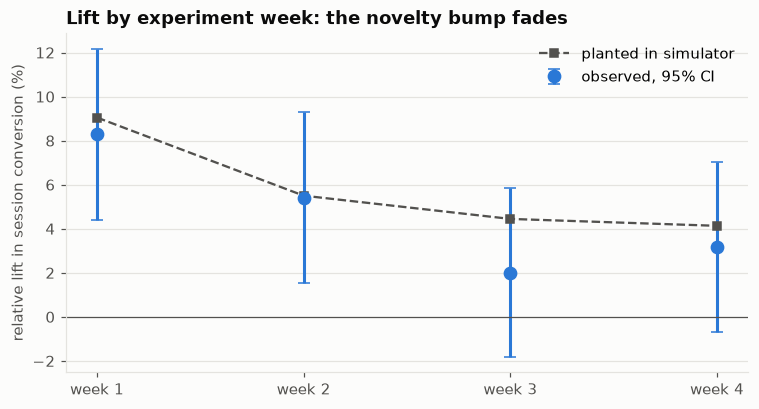

,control,treatment,relative lift,ci_low,ci_high,planted
week,,,,,,
1,33.17%,35.92%,+8.3%,+4.4%,+12.2%,+9.0%
2,33.25%,35.05%,+5.4%,+1.5%,+9.3%,+5.5%
3,33.89%,34.57%,+2.0%,-1.8%,+5.8%,+4.4%
4,33.19%,34.25%,+3.2%,-0.7%,+7.0%,+4.1%


In [13]:
es = exp_sessions.assign(
    day=(exp_sessions["started_at"] - cfg.experiment_start).dt.days,
    paid=exp_sessions["funnel_step"].eq("paid"),
)
es["week"] = es["day"] // 7 + 1

rows = []
for week, g in es.groupby("week"):
    c, t = g.loc[g["variant"] == "control", "paid"], g.loc[g["variant"] == "treatment", "paid"]
    r = two_proportion_ztest(int(c.sum()), len(c), int(t.sum()), len(t))
    planted_w = (uplift_multiplier(np.arange((week - 1) * 7, week * 7), cfg) - 1).mean()
    rows.append(
        {
            "week": week,
            "control": r.control,
            "treatment": r.treatment,
            "relative lift": r.relative,
            "ci_low": r.ci_low / r.control,
            "ci_high": r.ci_high / r.control,
            "planted": planted_w,
        }
    )
weekly = pd.DataFrame(rows).set_index("week")

fig, ax = plt.subplots()
ax.errorbar(
    weekly.index,
    weekly["relative lift"] * 100,
    yerr=[
        (weekly["relative lift"] - weekly["ci_low"]) * 100,
        (weekly["ci_high"] - weekly["relative lift"]) * 100,
    ],
    fmt="o",
    color=SERIES[0],
    markersize=8,
    capsize=4,
    linewidth=2,
    label="observed, 95% CI",
)
ax.plot(
    weekly.index,
    weekly["planted"] * 100,
    color=INK_SECONDARY,
    linestyle="--",
    marker="s",
    markersize=5,
    linewidth=1.5,
    label="planted in simulator",
)
ax.axhline(0, color=INK_SECONDARY, linewidth=0.8)
ax.set_xticks(weekly.index, [f"week {w}" for w in weekly.index])
ax.set_ylabel("relative lift in session conversion (%)")
ax.set_title("Lift by experiment week: the novelty bump fades")
ax.legend()
plt.show()
weekly.style.format(
    {c: "{:+.1%}" for c in ("relative lift", "ci_low", "ci_high", "planted")}
    | {"control": "{:.2%}", "treatment": "{:.2%}"}
)

Week 1 shows the largest lift and weeks 3–4 the smallest; each weekly interval is wide (a week is a quarter of
the sample), but the trend matches the planted novelty curve. These are session-level rates, used here only to
describe the shape over time. To estimate the effect that **lasts**, re-run the
primary metric on the second half of the window only (still merchant-level, still randomised — just a later slice):

In [14]:
late = exp_sessions[exp_sessions["started_at"] >= cfg.experiment_start + pd.Timedelta(days=14)]
late_m = merchant_metrics(late, orders.iloc[:0]).join(merchants["variant"])
lc, lt = late_m[late_m["variant"] == "control"], late_m[late_m["variant"] == "treatment"]
late_res = two_proportion_ztest(
    int(lc["converted"].sum()), len(lc), int(lt["converted"].sum()), len(lt)
)
print(
    f"days 15-28: control {late_res.control:.2%}, treatment {late_res.treatment:.2%}, "
    f"relative {late_res.relative:+.2%} (95% CI [{late_res.ci_low / late_res.control:+.2%}, {late_res.ci_high / late_res.control:+.2%}]), p = {late_res.p_value:.3f}"
)

days 15-28: control 45.54%, treatment 46.61%, relative +2.35% (95% CI [-0.44%, +5.13%]), p = 0.098


## 8 · Bayesian read-out (Beta-Binomial)

Same data, different question: *given what we saw, how likely is it that B is better, and what do we risk by shipping it?*
With a flat Beta(1, 1) prior the posterior for each arm is Beta(1 + conversions, 1 + non-conversions).

P(treatment > control)          = 0.99999
expected loss if we ship B      = 9.52e-09 (absolute conversion)
95% credible interval, relative = [+2.48%, +6.64%]
frequentist 95% CI, relative    = [+2.50%, +6.56%]


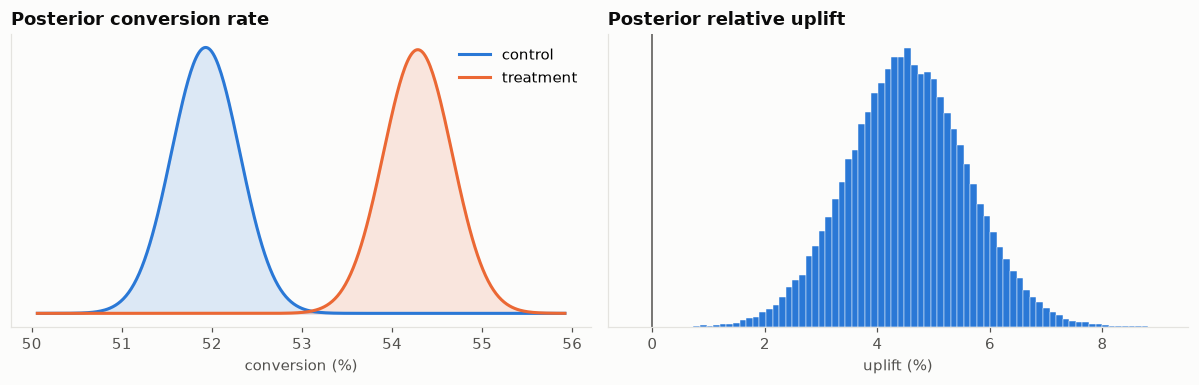

In [15]:
bayes = beta_binomial_ab(
    int(ctrl["converted"].sum()), len(ctrl), int(trt["converted"].sum()), len(trt), seed=1
)
print(f"P(treatment > control)          = {bayes.prob_treatment_better:.5f}")
print(
    f"expected loss if we ship B      = {bayes.expected_loss_treatment:.2e} (absolute conversion)"
)
print(f"95% credible interval, relative = [{bayes.uplift_ci[0]:+.2%}, {bayes.uplift_ci[1]:+.2%}]")
print(
    f"frequentist 95% CI, relative    = [{primary.ci_low / primary.control:+.2%}, {primary.ci_high / primary.control:+.2%}]"
)

draws_rng = np.random.default_rng(2)
pc = draws_rng.beta(bayes.alpha_c, bayes.beta_c, 100_000)
pt = draws_rng.beta(bayes.alpha_t, bayes.beta_t, 100_000)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
grid = np.linspace(min(pc.min(), pt.min()), max(pc.max(), pt.max()), 400)
for arm, a, b in (
    ("control", bayes.alpha_c, bayes.beta_c),
    ("treatment", bayes.alpha_t, bayes.beta_t),
):
    axes[0].plot(grid * 100, st.beta.pdf(grid, a, b), color=ARM_COLORS[arm], label=arm)
    axes[0].fill_between(grid * 100, st.beta.pdf(grid, a, b), color=ARM_COLORS[arm], alpha=0.15)
axes[0].set_title("Posterior conversion rate")
axes[0].set_xlabel("conversion (%)")
axes[0].legend()
axes[0].set_yticks([])
axes[1].hist((pt / pc - 1) * 100, bins=80, color=SERIES[0], edgecolor="white", linewidth=0.3)
axes[1].axvline(0, color=INK_SECONDARY, linewidth=1)
axes[1].set_title("Posterior relative uplift")
axes[1].set_xlabel("uplift (%)")
axes[1].set_yticks([])
plt.tight_layout()
plt.show()

With this much data and a flat prior, the Bayesian and frequentist intervals almost coincide, as they should.
The Bayesian framing adds two things stakeholders actually ask for: a direct probability that B is better, and the
**expected loss** — how much conversion we expect to give up if we ship B and are wrong. Here that loss is negligible.
What it does **not** give is a licence to peek: a posterior checked daily with a "stop when P > 95 %" rule also inflates
error rates.

## 9 · Why peeking inflates false positives

"Check the dashboard every day and stop when p < 0.05" feels harmless. It isn't. Simulate 2,000 **A/A tests**
(no true difference) with the same baseline and traffic as this experiment, and test after each of 28 daily looks:

false-positive rate, single test at day 28: 4.0%
false-positive rate, stop at first p<0.05:  25.7%  (5.1x the nominal 5%)


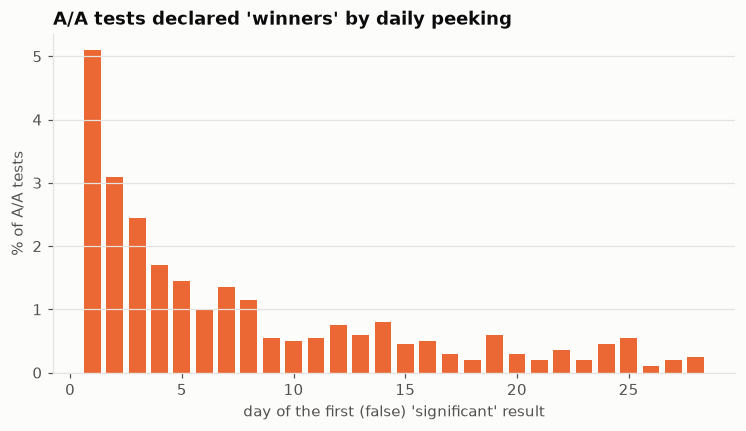

In [16]:
peek = simulate_peeking(
    p=baseline, n_per_arm=expected_per_arm, n_looks=28, n_sims=2_000, alpha=0.05, seed=3
)
print(f"false-positive rate, single test at day 28: {peek.false_positive_fixed:.1%}")
print(
    f"false-positive rate, stop at first p<0.05:  {peek.false_positive_peeking:.1%}  ({peek.false_positive_peeking / 0.05:.1f}x the nominal 5%)"
)

fig, ax = plt.subplots()
looks = np.bincount(peek.first_rejection_look, minlength=peek.n_looks + 1)[1:]
ax.bar(np.arange(1, peek.n_looks + 1), looks / peek.n_sims * 100, color=TREATMENT, width=0.75)
ax.set_xlabel("day of the first (false) 'significant' result")
ax.set_ylabel("% of A/A tests")
ax.set_title("A/A tests declared 'winners' by daily peeking")
plt.show()

Every look is another chance for noise to cross the line, and those chances add up. Most false wins come early,
when samples are small — precisely when the temptation to stop is strongest.

Valid alternatives when early stopping is a business need: group-sequential designs with an alpha-spending function
(O'Brien–Fleming), always-valid inference (mSPRT / confidence sequences), or a Bayesian decision rule on expected loss
with a pre-agreed threshold. This test was pre-registered as fixed-horizon, so it was read once, on day 28.

For contrast, this is the real experiment's cumulative p-value. It crosses 0.05 early — partly real effect, partly
the novelty bump — and a team stopping there would have reported an inflated lift.

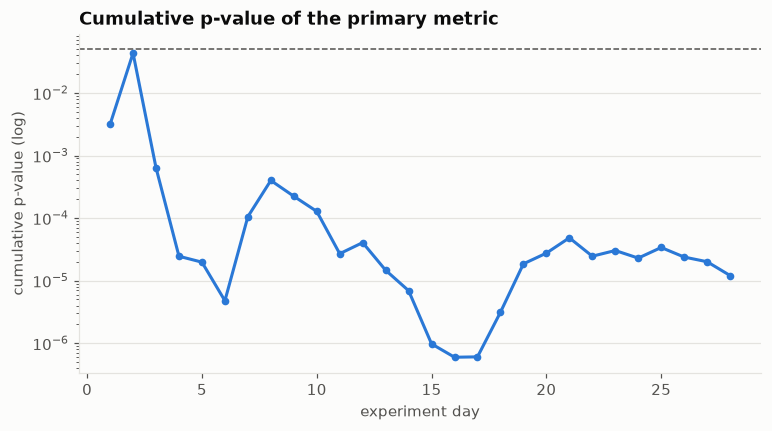

,p_value,relative
day,,
3,0.00064,+10.58%
7,0.00011,+7.77%
14,6.9e-06,+6.47%
21,4.8e-05,+4.80%
28,1.2e-05,+4.53%


In [17]:
first_seen = es.groupby("merchant_id")["day"].min()
first_paid = es[es["paid"]].groupby("merchant_id")["day"].min()
track = pd.DataFrame({"first_seen": first_seen, "first_paid": first_paid}).join(
    merchants["variant"]
)
rows = []
for d in range(cfg.exp_days):
    seen = track[track["first_seen"] <= d]
    conv = seen["first_paid"] <= d
    c, t = seen["variant"] == "control", seen["variant"] == "treatment"
    r = two_proportion_ztest(int(conv[c].sum()), int(c.sum()), int(conv[t].sum()), int(t.sum()))
    rows.append({"day": d + 1, "p_value": r.p_value, "relative": r.relative})
cum = pd.DataFrame(rows).set_index("day")

fig, ax = plt.subplots()
ax.plot(cum.index, cum["p_value"], color=SERIES[0], marker="o", markersize=4)
ax.axhline(0.05, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("experiment day")
ax.set_ylabel("cumulative p-value (log)")
ax.set_title("Cumulative p-value of the primary metric")
plt.show()
cum.loc[[3, 7, 14, 21, 28]].style.format({"p_value": "{:.2g}", "relative": "{:+.2%}"})

## 10 · Ground-truth check (only possible because the data is simulated)

The simulator multiplies the **details → payment submitted** probability of treated sessions by
`1 + true_uplift + novelty · 0.5^(day / half_life)`. Measuring that step directly should recover the planted value
averaged over when sessions happened.

In [18]:
details = es[es["funnel_step"].isin(["details", "payment_submitted", "paid"])].assign(
    submitted=lambda x: x["funnel_step"].isin(["payment_submitted", "paid"])
)
dc, dt = (details[details["variant"] == v]["submitted"] for v in ("control", "treatment"))
step = two_proportion_ztest(int(dc.sum()), len(dc), int(dt.sum()), len(dt))
planted_avg = (
    uplift_multiplier(details.loc[details["variant"] == "treatment", "day"].to_numpy(), cfg) - 1
).mean()
print(
    f"details → payment, relative lift: estimated {step.relative:+.2%} "
    f"(95% CI [{step.ci_low / step.control:+.2%}, {step.ci_high / step.control:+.2%}]), planted average {planted_avg:+.2%}"
)
print(f"planted steady-state effect (after novelty): {cfg.true_uplift:+.2%}")

details → payment, relative lift: estimated +5.07% (95% CI [+3.60%, +6.54%]), planted average +5.78%
planted steady-state effect (after novelty): +4.00%


The estimate brackets the planted value, and the steady-state effect sits inside the interval of the late-window
estimate from section 7. The merchant-level lift is smaller than the step-level one because a merchant with several sessions can
convert even if one session fails — the effect gets diluted when it is aggregated to the unit we care about.

## 11 · Decision write-up

**Recommendation: ship the one-page checkout**, plan for a lasting lift smaller than the headline number, and keep a
small holdout to watch cancellations.

| question | answer |
|---|---|
| Was the test valid? | Yes: no SRM (assignment p = 0.26), arms balanced in the pre-period (notebook 01), fixed 28-day horizon read once. |
| Primary metric | Merchant checkout conversion **51.9 % → 54.3 %**, +2.35 pp, **+4.5 % relative (95 % CI +2.5 % to +6.6 %)**, p ≈ 1e-5. Bayesian P(B > A) > 0.999, expected loss ≈ 0. |
| Secondary metric | GMV per merchant +4.5 % with CUPED (95 % CI +2.8 to +36.9 MXN per merchant, p = 0.02); the raw estimate was inconclusive (p = 0.13). CUPED cut variance by ~16 %. |
| Guardrails | Page-load p95 +1.8 % (limit +5 %); payment failures flat. Cancellations **flagged** (+15 %, p = 0.03; Holm-adjusted p = 0.06) with no mechanism linking them to checkout → monitor, not block. |
| How big is the lasting effect? | Smaller than +4.5 %. The lift decays week over week; on days 15–28 the merchant-level lift is +2.3 % (95 % CI −0.4 % to +5.1 %). Plan on **~2–3 %**, not 4.5 %. |

**Expected impact.** At the pre-period baseline, a +2–3 % relative lift means roughly 1–1.5 more converting merchants
per 100 who open checkout. Forecasts should use that range, not the full-window +4.5 %, which includes the novelty bump.

**Follow-ups**

1. Roll out to 95 % and keep a **5 % holdout for 4 weeks** to measure the post-novelty effect directly and to
   re-check the cancellation rate at the merchant level.
2. Add the Holm correction for guardrails and a merchant-level (delta-method) estimator for ratio metrics to the
   pre-registration template.
3. Find a stronger CUPED covariate for conversion (e.g. pre-period sessions, or a CUPAC-style model prediction): the
   binary pre-conversion indicator only removed ~3 % of the variance.

*Ground truth check:* the simulator planted +4 % lasting and +8 % decaying novelty on the details → payment step.
The step-level estimate (+5.1 %, CI +3.6 % to +6.5 %) brackets the planted average (+5.8 %), and the late-window
read correctly suggests a smaller lasting effect. None of the numbers here describe a real product.
